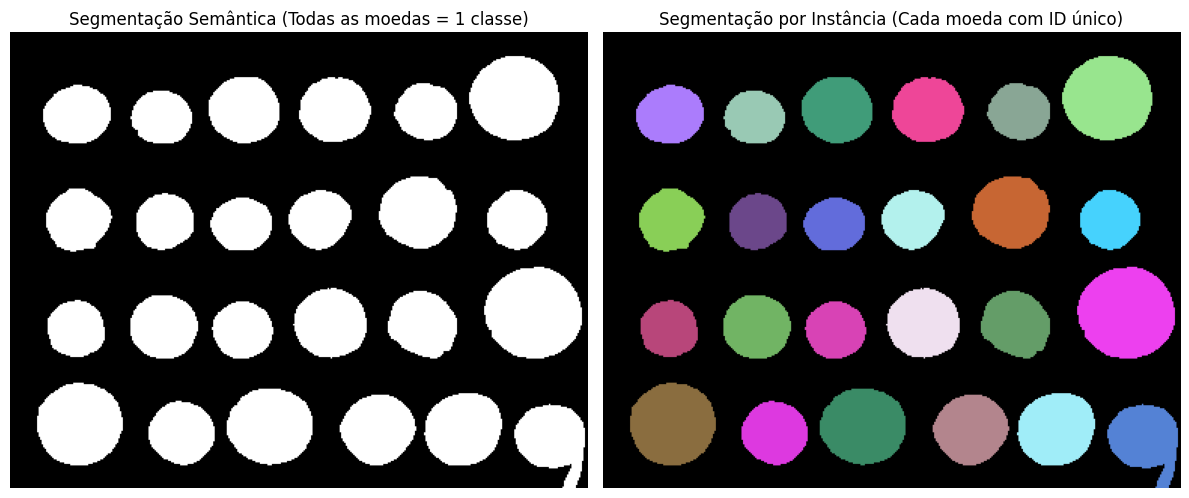

In [6]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

try:
    segmentacao_semantica = img_moedas_contornos.copy()
except NameError:
    mascara_moedas_adapt = cv2.adaptiveThreshold(cv2.GaussianBlur(data.coins(), (5,5), 0), 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 101, -10)
    mascara_moedas_contornos, _ = cv2.findContours(mascara_moedas_adapt, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    moedas_contornos = [c for c in mascara_moedas_contornos if cv2.contourArea(c) > 500]
    img_moedas_contornos = np.zeros_like(mascara_moedas_adapt)
    cv2.drawContours(img_moedas_contornos, moedas_contornos, -1, 255, thickness=-1)
    segmentacao_semantica = img_moedas_contornos.copy()

num_labels, segmentacao_instancia = cv2.connectedComponents(segmentacao_semantica)

cores_instancias = np.zeros((segmentacao_instancia.shape[0], segmentacao_instancia.shape[1], 3), dtype=np.uint8)
np.random.seed(42)
for label in range(1, num_labels):
    cores_instancias[segmentacao_instancia == label] = np.random.randint(50, 255, size=3)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(segmentacao_semantica, cmap='gray')
plt.title('Segmentação Semântica (Todas as moedas = 1 classe)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cores_instancias)
plt.title('Segmentação por Instância (Cada moeda com ID único)')
plt.axis('off')

plt.tight_layout()
plt.show()

### 2. Teste com outra imagem do skimage (`data.horse`)

Aplicaremos o mesmo princípio para a imagem do cavalo (`data.horse()`), que possui uma estrutura de objeto diferente.

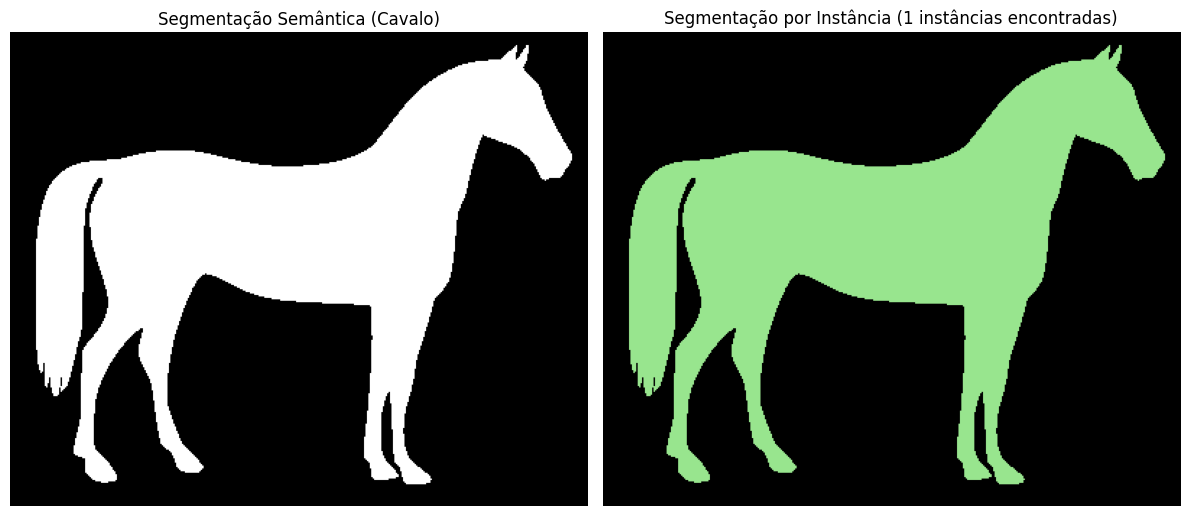

In [7]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

img_cavalo = data.horse()
img_cavalo_binaria = (~img_cavalo).astype(np.uint8) * 255

semantica_cavalo = img_cavalo_binaria.copy()

num_labels_cavalo, instancia_cavalo = cv2.connectedComponents(semantica_cavalo)

cores_instancias_cavalo = np.zeros((instancia_cavalo.shape[0], instancia_cavalo.shape[1], 3), dtype=np.uint8)
np.random.seed(42)
for label in range(1, num_labels_cavalo):
    cores_instancias_cavalo[instancia_cavalo == label] = np.random.randint(50, 255, size=3)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(semantica_cavalo, cmap='gray')
plt.title('Segmentação Semântica (Cavalo)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cores_instancias_cavalo)
plt.title(f'Segmentação por Instância ({num_labels_cavalo - 1} instâncias encontradas)')
plt.axis('off')

plt.tight_layout()
plt.show()

### Análise Comparativa Simplificada

* **Moedas**: Como existem múltiplos objetos separados, a **segmentação por instância** é fundamental para diferenciar e contar cada uma das moedas individualmente (atribuindo cores únicas).
* **Cavalo**: Como há apenas um único objeto contínuo na imagem, o resultado de ambas as segmentações é praticamente o mesmo, já que o algoritmo detecta apenas 1 única instância.